<a href="https://colab.research.google.com/github/jjyjung/ai/blob/gh-pages/pytorch_CNN_CUB200.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Google Drive 마운트

Google Drive를 Colab에 연결합니다. 실행 시 Google 계정 인증을 완료해야 합니다.

In [1]:
from google.colab import drive
drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


### 이미지 파일 압축 해제

Google Drive에 저장된 CUB200.zip을 데이터 폴더에 압축 해제합니다. 이미 압축을 풀었다면 이 셀은 건너뜁니다.

In [4]:
# 필요할 때만 주석을 해제해 실행하세요.
#!unzip '/content/gdrive/My Drive/Colab Notebooks/ai/CNN/CUB200.zip' -d '/content/gdrive/My Drive/Colab Notebooks/ai/CNN/CUB200'

## CUB200-2011 데이터셋

CalTech에서 구축한 새 품종 분류 데이터셋 (새 200종의 이미지 11788장)

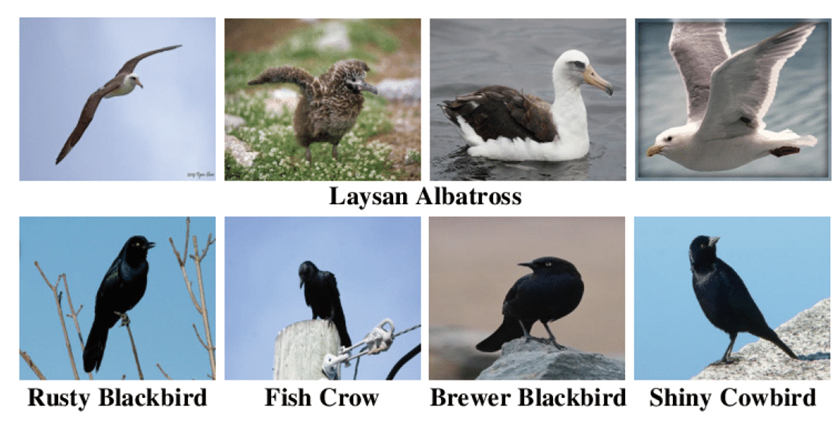

학습에 필요한 PyTorch 라이브러리, 전처리(transforms) 도구, 그리고 CUB200 커스텀 데이터셋 클래스를 정의합니다. 또한 전체 클래스 중 테스트용으로 일부 비율(10%)만 선택하여 데이터 로더(DataLoader)를 빌드합니다.

In [6]:
import os
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import models, transforms
from torchvision.models import ResNet50_Weights

# Google Drive에 둔 CUB200 데이터 경로
data_dir = "/content/gdrive/My Drive/Colab Notebooks/ai/CNN/"
train_folder = os.path.join(data_dir, 'CUB200', 'train')
test_folder = os.path.join(data_dir, 'CUB200', 'test')

class_reduce = 0.1  # 테스트를 위해 전체 클래스 중 10%만 사용
all_classes = sorted(name for name in os.listdir(train_folder)
                     if os.path.isdir(os.path.join(train_folder, name)))
num_class = max(1, int(len(all_classes) * class_reduce))
class_names = all_classes[:num_class]
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

# ImageNet 사전학습 ResNet50의 입력 정규화
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

class CUB200Dataset(Dataset):
    def __init__(self, root, class_names, class_to_idx, transform):
        self.samples = []
        self.transform = transform
        for class_name in class_names:
            class_dir = os.path.join(root, class_name)
            if not os.path.isdir(class_dir):
                continue
            for filename in sorted(os.listdir(class_dir)):
                path = os.path.join(class_dir, filename)
                if not os.path.isfile(path):
                    continue
                try:
                    with Image.open(path) as image:
                        if image.mode != 'RGB':
                            print(f"주의: RGB 영상이 아니어서 제외합니다: {class_name}/{filename}")
                            continue
                except (OSError, ValueError):
                    print(f"주의: 읽을 수 없는 영상이어서 제외합니다: {class_name}/{filename}")
                    continue
                self.samples.append((path, class_to_idx[class_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        with Image.open(path) as image:
            image = image.convert('RGB')
            image = self.transform(image)
        return image, label

train_dataset = CUB200Dataset(train_folder, class_names, class_to_idx, image_transform)
test_dataset = CUB200Dataset(test_folder, class_names, class_to_idx, image_transform)

# 공식 train 폴더에서 클래스별 10%를 validation으로 분리 (재현 가능)
indices_by_class = {}
for index, (_, label) in enumerate(train_dataset.samples):
    indices_by_class.setdefault(label, []).append(index)

rng = np.random.default_rng(42)
train_indices, val_indices = [], []
for class_indices in indices_by_class.values():
    class_indices = np.array(class_indices)
    rng.shuffle(class_indices)
    val_count = max(1, int(round(len(class_indices) * 0.1)))
    val_indices.extend(class_indices[:val_count].tolist())
    train_indices.extend(class_indices[val_count:].tolist())

train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(train_dataset, val_indices)

batch_size = 12
train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"사용 장치: {device}")
print(f"클래스 수: {num_class}, 학습 이미지: {len(train_subset)}, "
      f"검증 이미지: {len(val_subset)}, 테스트 이미지: {len(test_dataset)}")

사용 장치: cuda
클래스 수: 20, 학습 이미지: 540, 검증 이미지: 60, 테스트 이미지: 515


DataLoader에서 미니배치를 하나 가져와 전처리 후 이미지 텐서와 정답 레이블의 크기를 확인합니다.

In [7]:
sample_images, sample_labels = next(iter(train_loader))
print(f"이미지 텐서 크기: {tuple(sample_images.shape)}")
print(f"레이블 텐서 크기: {tuple(sample_labels.shape)}")

이미지 텐서 크기: (12, 3, 224, 224)
레이블 텐서 크기: (12,)


테스트 데이터셋의 클래스별 이미지 개수를 확인합니다.

In [8]:
for class_name in class_names:
    class_dir = os.path.join(test_folder, class_name)
    count = len([name for name in os.listdir(class_dir)
                 if os.path.isfile(os.path.join(class_dir, name))]) if os.path.isdir(class_dir) else 0
    print(f"{class_name}	테스트 파일 개수: {count}")

001.Black_footed_Albatross	테스트 파일 개수: 30
002.Laysan_Albatross	테스트 파일 개수: 30
003.Sooty_Albatross	테스트 파일 개수: 28
004.Groove_billed_Ani	테스트 파일 개수: 30
005.Crested_Auklet	테스트 파일 개수: 14
006.Least_Auklet	테스트 파일 개수: 11
007.Parakeet_Auklet	테스트 파일 개수: 23
008.Rhinoceros_Auklet	테스트 파일 개수: 18
009.Brewer_Blackbird	테스트 파일 개수: 29
010.Red_winged_Blackbird	테스트 파일 개수: 30
011.Rusty_Blackbird	테스트 파일 개수: 30
012.Yellow_headed_Blackbird	테스트 파일 개수: 26
013.Bobolink	테스트 파일 개수: 30
014.Indigo_Bunting	테스트 파일 개수: 30
015.Lazuli_Bunting	테스트 파일 개수: 28
016.Painted_Bunting	테스트 파일 개수: 28
017.Cardinal	테스트 파일 개수: 27
018.Spotted_Catbird	테스트 파일 개수: 15
019.Gray_Catbird	테스트 파일 개수: 29
020.Yellow_breasted_Chat	테스트 파일 개수: 29


## 전이학습 (Transfer Learning)

ImageNet으로 사전학습된 ResNet50 백본을 가져와서 가중치를 동결(Freeze)할지 여부를 결정하고, 기존 분류층을 제거(`nn.Identity`)한 뒤 우리의 타깃 클래스 개수에 맞는 커스텀 분류층을 연결한 모델을 생성합니다.



In [9]:
def build_resnet50_transfer(num_classes, freeze_backbone=True):
    backbone = models.resnet50(weights=ResNet50_Weights.DEFAULT)
    feature_count = backbone.fc.in_features
    backbone.fc = nn.Linear(feature_count, num_classes)

    if freeze_backbone:
        for name, parameter in backbone.named_parameters():
            parameter.requires_grad = name.startswith('fc.')

    return backbone

cnn = build_resnet50_transfer(num_class, freeze_backbone=True).to(device)

In [10]:
# def build_resnet50_transfer(num_classes, freeze_backbone=True):
#     weights = ResNet50_Weights.DEFAULT
#     backbone = models.resnet50(weights=weights)
#     feature_count = backbone.fc.in_features
#     # (Keras의 include_top=False처럼) 7x7 특징맵을 유지하도록 GAP를 제거
#     backbone.avgpool = nn.Identity()
#     backbone.fc = nn.Identity()  # ResNet50의 기존 분류층 제거

#     if freeze_backbone:
#         for parameter in backbone.parameters():
#             parameter.requires_grad = False

#     # (Keras 예제의 Flatten -> Dense(1024, ReLU) -> Dense(num_classes)에 대응)
#     model = nn.Sequential(
#         backbone,
#         nn.Flatten(),
#         nn.Linear(feature_count * 7 * 7, 1024),
#         nn.ReLU(inplace=True),
#         nn.Linear(1024, num_classes),
#     )
#     return model

# cnn = build_resnet50_transfer(num_class, freeze_backbone=True).to(device)

모델의 계층 구성을 출력하고, 전체 파라미터 개수 및 가중치 동결 설정에 따른 학습 가능한(Trainable) 파라미터 개수를 계산하여 비교합니다.

ResNet50의 최종 합성곱 특징맵 크기는 입력 크기 224×224 기준 2048×7×7입니다.

In [11]:
print(cnn)
total_params = sum(parameter.numel() for parameter in cnn.parameters())
trainable_params = sum(parameter.numel() for parameter in cnn.parameters() if parameter.requires_grad)
print(f"전체 파라미터 수: {total_params:,}")
print(f"학습 가능한 파라미터 수: {trainable_params:,}")

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

## ResNet50 Architecture
2015년 ILSVRC에서 5순위 정확도에서 3.5%로 우승한 Microsoft의 개발 모형

residual learning을 적용하여 간단한 학습 형태로 전이학습에 널리 사용되고 있음

#### Residual learning (잔차학습) 또는 skip connection
기울기 소실을 막기 위하여 컨볼루션층과 병렬로 원본 데이터를 더해주는 설계 기법

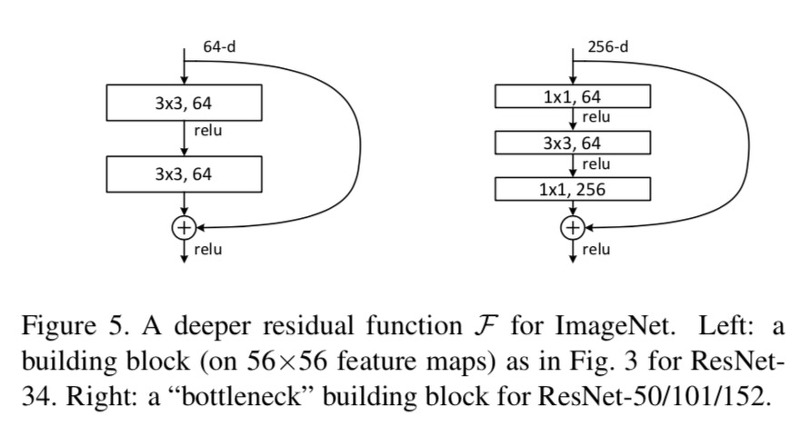

- 왼쪽: 기본 블록 — 56×56 특징맵에서 3×3 합성곱 두 번을 적용합니다. 두 합성곱 모두 채널 수가 64이므로, 입력(64채널)을 변환 결과에 그대로 더할 수 있습니다. 이 형태는 그림 설명처럼 ResNet-34에서 사용됩니다.
- 오른쪽: 병목 블록(bottleneck) — 입력 256채널을 1×1 합성곱으로 64채널까지 줄이고, 3×3 합성곱으로 특징을 처리한 뒤, 다시 1×1 합성곱으로 256채널로 늘립니다. 따라서 입력과 변환 결과를 더할 수 있습니다. 이 구조는 ResNet-50/101/152에서 사용됩니다.
- 두 경우 모두 합산 후 ReLU를 적용합니다. 병목 블록은 가운데 3×3 합성곱이 적은 채널을 처리하게 해 계산량을 줄이면서, 더 깊은 네트워크를 구성할 수 있게 합니다.

#### ResNet50의 구조
총 50개의 학습 계층을 포함

1 conv => 1개

Stage 1 : 3 conv * 3 block => 9개

Stage 2 : 3 conv * 4 block => 12개

Stage 3 : 3 conv * 6 block => 18개

Stage 4 : 3 conv * 3 block => 9개

1 FC => 1개

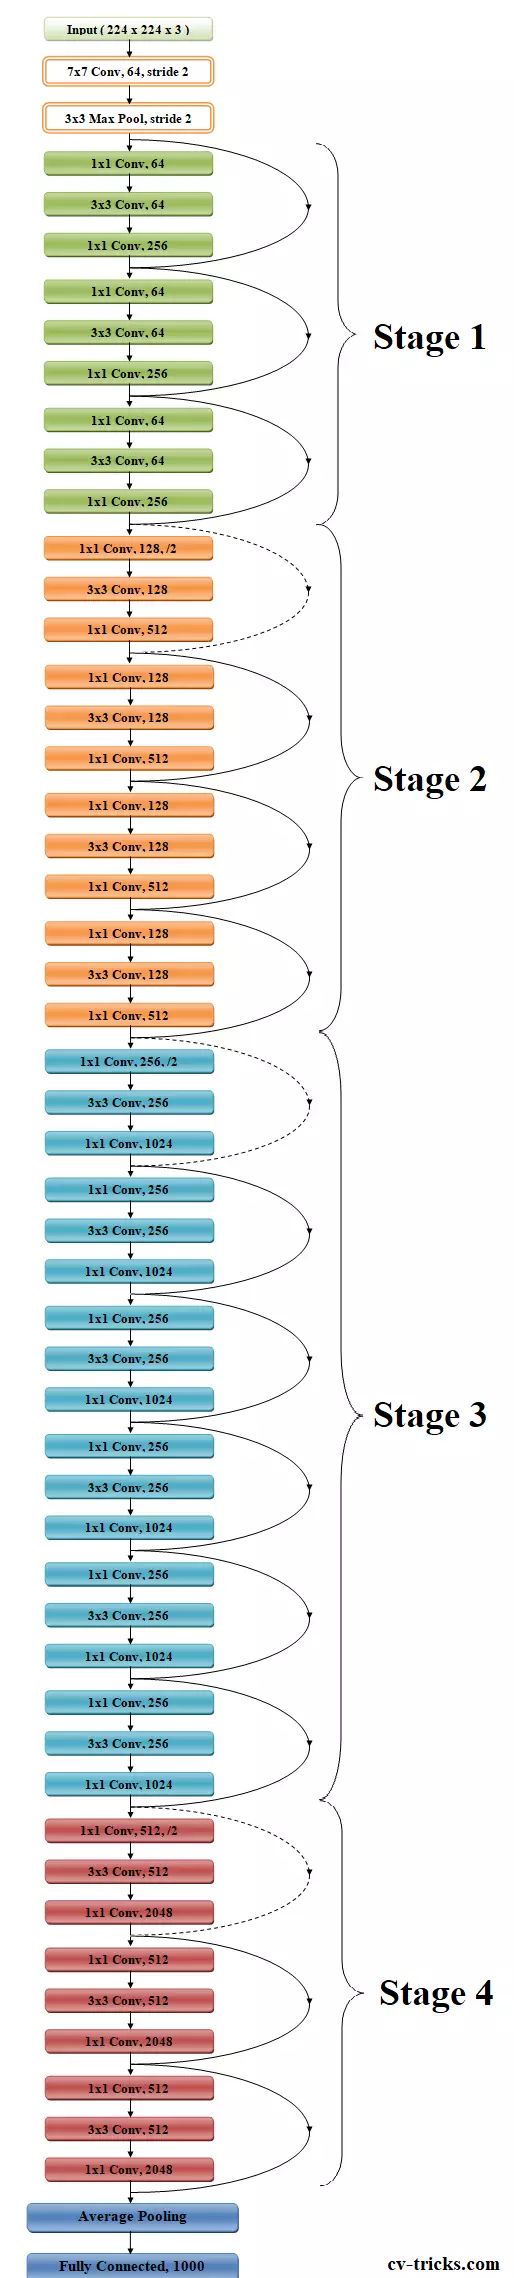

#### Global Average Pooling (GAP)
ResNet은 FC의 parameter를 줄이기 위하여 Global Average Pooling을 사용함

각 Feature map의 평균값을 단일 노드로 매핑하는 방법

https://alexisbcook.github.io/2017/global-average-pooling-layers-for-object-localization/

https://github.com/keras-team/keras/issues/7920

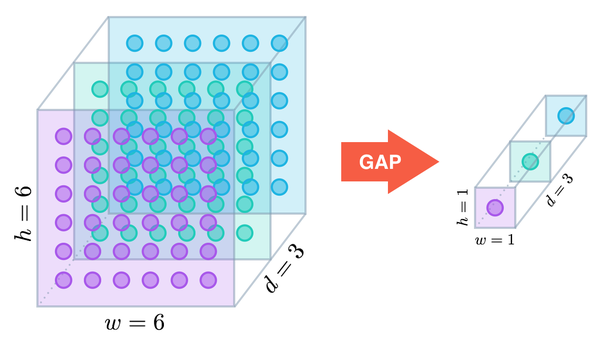

#### Batch Normalization (BN)

배치별로 평균과 분산을 이용해 정규화하여 layer를 규제(regularization)하는 기법

정규화한 후, Scale 및 Shift 파라미터는 학습시킴

Dropout보다 성능이 우수함 (Dropout 대체하여 사용)

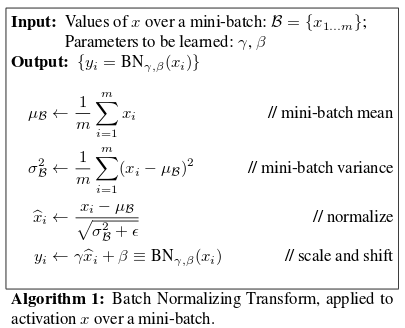

ResNet50 커스텀 백본 구조 및 파라미터 확인

In [12]:
print("모델의 최종 분류층(FC):", cnn.fc)

# 전체 파라미터 수에서 fc(분류층) 파라미터 수를 제외하여 백본 파라미터 수를 계산합니다.
total_params = sum(parameter.numel() for parameter in cnn.parameters())
fc_params = sum(parameter.numel() for parameter in cnn.fc.parameters())
backbone_params = total_params - fc_params

print("파라미터 수: ")
print(f"total_params = {total_params:,}")
print(f"fc_params = {fc_params:,}")
print(f"backbone_params = {backbone_params:,}")

모델의 최종 분류층(FC): Linear(in_features=2048, out_features=20, bias=True)
파라미터 수: 
total_params = 23,549,012
fc_params = 40,980
backbone_params = 23,508,032


에폭(Epoch)별 학습 및 검증 데이터에 대한 정확도(Accuracy)와 손실(Loss) 변화 추이를 Matplotlib 그래프로 그려주는 함수를 정의합니다.

학습 코드가 history 딕셔너리에 기록한 값을 사용합니다.

In [13]:
def draw_plot(history):
    plt.figure(figsize=(7, 4))
    plt.plot(history['accuracy'], label='Train')
    plt.plot(history['val_accuracy'], label='Validation')
    plt.title('Model accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='best')
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(7, 4))
    plt.plot(history['loss'], label='Train')
    plt.plot(history['val_loss'], label='Validation')
    plt.title('Model loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='best')
    plt.grid(True)
    plt.show()

#### Freezing 시킨 Transfer Learning (전이학습) 결과

ResNet50 백본을 고정한 채 분류층만 학습합니다. 검증 손실이 10회 연속 개선되지 않으면 조기 종료하고, 검증 손실이 가장 낮았던 모델을 복원합니다.

1에폭 동안 학습/평가를 수행하는 `run_epoch`와 조기 종료(Early Stopping) 기법이 적용된 `fit_model` 함수를 구현하여, 백본 가중치가 고정된 상태에서의 분류층 학습을 실행하고 최종 테스트 정확도를 평가합니다.

Epoch 001/100 - loss: 3.0051 - accuracy: 0.0389 - val_loss: 2.9898 - val_accuracy: 0.0333
Epoch 002/100 - loss: 2.9779 - accuracy: 0.0667 - val_loss: 2.9621 - val_accuracy: 0.0667
Epoch 003/100 - loss: 2.9527 - accuracy: 0.1037 - val_loss: 2.9474 - val_accuracy: 0.1000
Epoch 004/100 - loss: 2.9272 - accuracy: 0.1241 - val_loss: 2.9235 - val_accuracy: 0.1333
Epoch 005/100 - loss: 2.9067 - accuracy: 0.1574 - val_loss: 2.9038 - val_accuracy: 0.1500
Epoch 006/100 - loss: 2.8802 - accuracy: 0.2019 - val_loss: 2.8826 - val_accuracy: 0.1667
Epoch 007/100 - loss: 2.8606 - accuracy: 0.2352 - val_loss: 2.8645 - val_accuracy: 0.2167
Epoch 008/100 - loss: 2.8329 - accuracy: 0.2963 - val_loss: 2.8463 - val_accuracy: 0.2500
Epoch 009/100 - loss: 2.8107 - accuracy: 0.3222 - val_loss: 2.8251 - val_accuracy: 0.2667
Epoch 010/100 - loss: 2.7953 - accuracy: 0.3648 - val_loss: 2.8071 - val_accuracy: 0.2500
Epoch 011/100 - loss: 2.7713 - accuracy: 0.4000 - val_loss: 2.7843 - val_accuracy: 0.3333
Epoch 012/

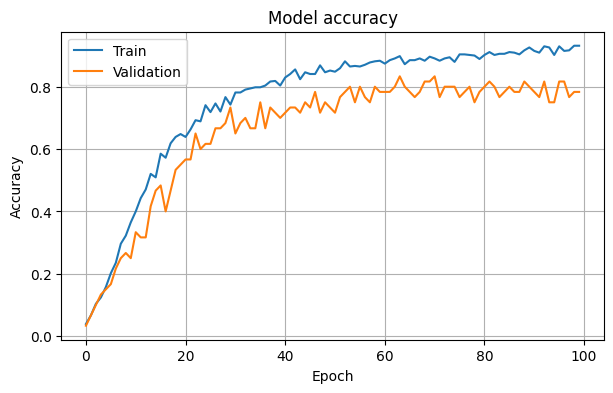

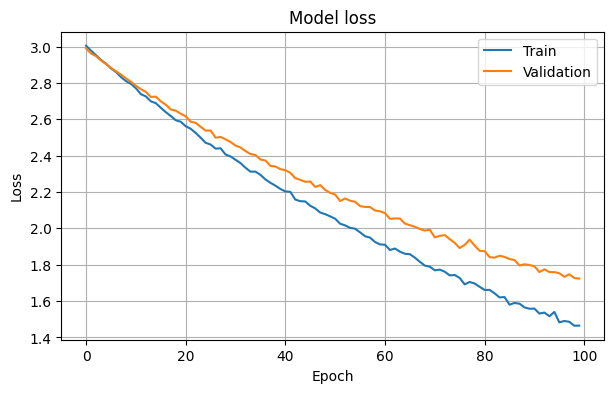

In [14]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None   # None이 아니면 True, None이면 False
    model.train(is_training)   # True일 때만 학습 모드
    total_loss, total_correct, total_count = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        if is_training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(is_training):
            logits = model(images)
            loss = criterion(logits, labels)
            if is_training:
                loss.backward()
                optimizer.step()
        batch_count = labels.size(0)
        total_loss += loss.item() * batch_count
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_count += batch_count

    return total_loss / total_count, total_correct / total_count  # 평균 loss 및 accuracy 반환


def fit_model(model, epochs=100, patience=10, learning_rate=0.00002):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        (parameter for parameter in model.parameters() if parameter.requires_grad),
        lr=learning_rate,
    )  # requires_grad=True인 파라미터만 선택. 백본을 고정한 학습에서는 새 FC층의 파라미터만 선택됨.
    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    best_val_loss = float('inf')  # 무한대로 초기화
    best_weights = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0

    for epoch in range(epochs):
        train_loss, train_accuracy = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_accuracy = run_epoch(model, val_loader, criterion)
        history['loss'].append(train_loss)
        history['accuracy'].append(train_accuracy)
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_accuracy)
        print(f"Epoch {epoch + 1:03d}/{epochs} - "
              f"loss: {train_loss:.4f} - accuracy: {train_accuracy:.4f} - "
              f"val_loss: {val_loss:.4f} - val_accuracy: {val_accuracy:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print(f"검증 손실이 개선되지 않아 {epoch + 1} 에폭에서 조기 종료합니다.")
                break

    model.load_state_dict(best_weights)
    return history

history = fit_model(cnn, 100)
_, test_accuracy = run_epoch(cnn, test_loader, nn.CrossEntropyLoss())
print(f"정확률(%): {test_accuracy * 100:.2f}")
draw_plot(history)

### 혼동 행렬(Confusion Matrix) 생성 및 평가
테스트 이미지에 대한 예측으로 혼동행렬을 계산합니다. 행은 예측 클래스, 열은 실제 클래스를 나타내며, 대각선 합으로 정확도를 계산합니다.

In [15]:
def make_confusion_matrix(model, loader, num_classes):
    model.eval()
    confusion = np.zeros((num_classes, num_classes), dtype=np.int64)
    with torch.no_grad():
        for images, labels in loader:
            logits = model(images.to(device))
            predictions = logits.argmax(dim=1).cpu().numpy()
            actual = labels.numpy()
            np.add.at(confusion, (predictions, actual), 1)
    return confusion

conf = make_confusion_matrix(cnn, test_loader, num_class)
print(conf)
accuracy = np.trace(conf) / conf.sum()
print(f"정확도(%): {accuracy * 100:.2f}")

[[21  5  2  0  0  0  0  3  0  0  1  0  0  0  0  0  0  0  0  0]
 [ 3 25  6  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 6  0 19  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 28  0  0  0  0  2  4  3  0  1  0  0  0  0  0  1  0]
 [ 0  0  0  0 11  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  9  4  0  0  0  0  0  0  0  0  1  0  0  0  0]
 [ 0  0  0  0  0  1 18  3  1  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  1  1  3  1  1 12  2  0  0  0  0  0  0  0  0  0  0  1]
 [ 0  0  0  1  0  0  0  0 14  3  2  3  1  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  1 16  3  0  0  0  1  0  0  0  2  0]
 [ 0  0  0  0  0  0  0  0  4  1 20  1  0  0  0  1  0  0  1  1]
 [ 0  0  0  0  0  0  0  0  0  3  0 17  0  0  0  0  0  0  0  2]
 [ 0  0  0  0  0  0  0  0  1  2  0  3 26  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0 30  1  0  0  0  1  0]
 [ 0  0  0  0  0  0  0  0  0  0  1  0  1  0 26  1  0  0  1  2]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 20  2  0

### Fine-tuning 시키는 Transfer Learning (전이학습) 결과

백본 가중치의 동결을 해제(`freeze_backbone=False`)하여 피쳐 추출기 영역을 포함한 전체 네트워크가 새 품종 데이터셋에 맞게 미세하게 조정되도록 새로 모델을 빌드하고 학습을 진행합니다.


ImageNet 사전학습 ResNet50을 새로 불러와 백본의 가중치도 학습할 수 있게 둡니다. 앞선 고정 백본 전이학습과 달리 전체 네트워크를 미세조정합니다.

Epoch 001/100 - loss: 2.9800 - accuracy: 0.0630 - val_loss: 2.9281 - val_accuracy: 0.1000
Epoch 002/100 - loss: 2.8305 - accuracy: 0.2981 - val_loss: 2.7997 - val_accuracy: 0.3000
Epoch 003/100 - loss: 2.6069 - accuracy: 0.5944 - val_loss: 2.5415 - val_accuracy: 0.6833
Epoch 004/100 - loss: 2.2584 - accuracy: 0.8056 - val_loss: 2.1380 - val_accuracy: 0.7667
Epoch 005/100 - loss: 1.8285 - accuracy: 0.8944 - val_loss: 1.7055 - val_accuracy: 0.7833
Epoch 006/100 - loss: 1.4061 - accuracy: 0.9407 - val_loss: 1.3221 - val_accuracy: 0.8167
Epoch 007/100 - loss: 1.0150 - accuracy: 0.9389 - val_loss: 1.0240 - val_accuracy: 0.8500
Epoch 008/100 - loss: 0.7223 - accuracy: 0.9685 - val_loss: 0.8224 - val_accuracy: 0.8667
Epoch 009/100 - loss: 0.5446 - accuracy: 0.9759 - val_loss: 0.7208 - val_accuracy: 0.8667
Epoch 010/100 - loss: 0.3677 - accuracy: 0.9852 - val_loss: 0.6025 - val_accuracy: 0.8833
Epoch 011/100 - loss: 0.2862 - accuracy: 0.9926 - val_loss: 0.5404 - val_accuracy: 0.8833
Epoch 012/

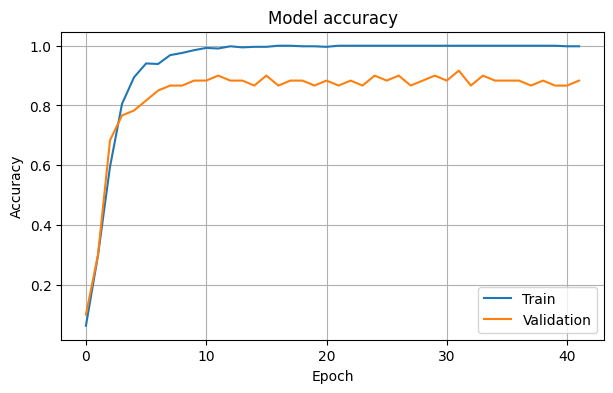

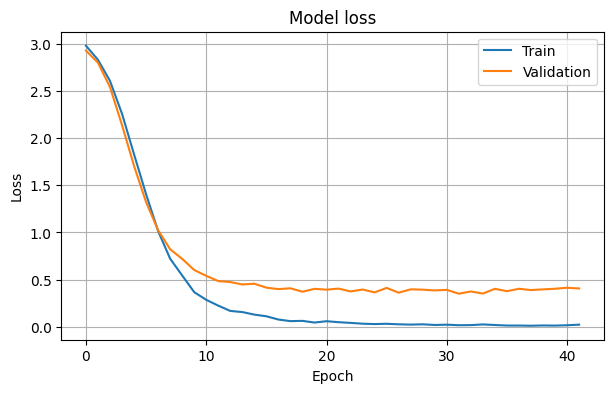

In [16]:
cnn2 = build_resnet50_transfer(num_class, freeze_backbone=False).to(device)
history2 = fit_model(cnn2, 100, learning_rate=0.00002)
_, test_accuracy2 = run_epoch(cnn2, test_loader, nn.CrossEntropyLoss())
print(f"정확률(%): {test_accuracy2 * 100:.2f}")
draw_plot(history2)

미세조정한 모델의 테스트 예측으로 혼동행렬과 전체 정확도를 계산합니다.

In [17]:
conf2 = make_confusion_matrix(cnn2, test_loader, num_class)
print(conf2)
accuracy2 = np.trace(conf2) / conf2.sum()
print(f"정확도(%): {accuracy2 * 100:.2f}")

[[23  1  2  0  0  1  0  1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1 24  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 6  4 25  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 30  0  0  0  0  1  0  3  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 12  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 10  0  1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 22  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  1  0  1 16  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0 20  1  8  0  0  0  0  0  0  0  1  0]
 [ 0  0  0  0  0  0  0  0  0 28  0  1  1  0  0  0  0  0  0  0]
 [ 0  1  0  0  0  0  0  0  5  1 19  1  2  0  0  0  0  0  1  1]
 [ 0  0  0  0  0  0  0  0  0  0  0 24  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0 26  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  2  0  0  0  0 30  2  0  0  0  1  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0 26  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 27  0  0